<a href="https://colab.research.google.com/github/mike23199/motorsport-telemetry-python-analysis-ml/blob/main/01_eda_and_data_validation/01_EDA_and_Data_Validation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 01. Exploratory Data Analysis (EDA) & Data Validation

**Objective:** Inspect the raw AiM `.xrk` telemetry structure, verify sensor data quality, identify inactive channels, and perform statistical sanity checks prior to data cleaning.

In [9]:
# Install libxrk (only needed once per Colab session)
!pip install libxrk

## 1. Data Ingestion & Session Metadata
We begin by loading the raw `.xrk` telemetry file using the `logger_data` wrapper and inspecting session-level metadata (rider, track, vehicle, and logging details).

In [10]:
from logger_data import Session, validate

# We put here the name of one of the files
filename = "Lambros_testing_0356.xrk"

session = Session(filename)

print("1. GENERAL INFO (Metadata):")
for key, value in session.metadata.items():
    print(f"   {key}: {value}")

1. GENERAL INFO (Metadata):
   Format: AiM XRK File
   Session: Serres 
   Vehicle: Orange
   Racer: Lambros
   Championship: NA
   Comment: 
   Date: Monday, March 23, 2026
   Time: 11:15 AM
   Sample Rate: 20
   Duration: 915.935
   Segment: Session
   Beacon Markers: [249.456, 357.561, 460.242, 563.15, 667.237, 766.973, 915.935]
   Segment Times: [249.456, 108.105, 102.681, 102.908, 104.087, 99.736, 148.962]
   Datetime: 2026-03-23 11:15:01
   XRK: {'Driver': 'Lambros', 'Vehicle': 'Orange', 'Log Date': '03/23/2026', 'Log Time': '11:15:01', 'Session': 'Generic testing', 'Series': 'NA', 'Long Comment': '', 'Venue': 'Serres ', 'Odo/System Distance (km)': 684.965, 'Odo/System Time': '9:43:52', 'Odo/Usr 1 Distance (km)': 684.965, 'Odo/Usr 1 Time': '9:43:52', 'Odo/Usr 2 Distance (km)': 684.965, 'Odo/Usr 2 Time': '9:43:52', 'Odo/Usr 3 Distance (km)': 684.965, 'Odo/Usr 3 Time': '9:43:52', 'Odo/Usr 4 Distance (km)': 684.965, 'Odo/Usr 4 Time': '9:43:52', 'Logger ID': 4506131, 'Logger Model ID

## 2. Dataset Dimensions & Schema Inspection
Next, we inspect the primary time-series DataFrame (`session.data`) to check its dimensions (samples vs. channels), preview the initial rows, and build a complete Data Dictionary mapping each channel to its physical measurement unit.

In [11]:
# Check dataset dimensions (rows = 20Hz time samples, columns = telemetry channels), size of session.data, total rows, columns
print("Dataset Dimensions (Rows, Columns):", session.data.shape)

# Top 5 rows of the object
display(session.data.head())

# Map every telemetry channel to its corresponding measurement unit
print("\n=== CHANNEL DATA DICTIONARY ===")
for col in session.data.columns:
    unit = session.units.get(col, "Dimensionless / Calculated")
    print(f"  {col:<20} ---> [{unit}]")

Dataset Dimensions (Rows, Columns): (10350, 71)


,lap,lap_elapsed,Predictive Time,Best Run Diff,Best Today Diff,Prev Lap Diff,Ref Lap Diff,External Voltage,RPM,Brake_pressure,...,GPS_pDOP,GPS PosAccuracy,GPS SpdAccuracy,GPS_InlineAcc,GPS_LateralAcc,GPS_Yaw_Rate,GPS_ITOW,GPS_Week,distance,lap_distance
Time,,,,,,,,,,,,,,,,,,,,,
249.50,1,0.044,-12290.0,-12290.0,-12290.0,-12290.0,-12290.0,10.77404,0.0,0.093834,...,1.33,4.1,0.13,0.106963,0.040747,0.522797,120013680.0,2411.0,3241.69,1.93
249.55,1,0.094,-12290.0,-12290.0,-12290.0,-12290.0,-12290.0,10.77204,0.0,0.165305,...,1.33,4.1,0.13,-0.062719,-0.026274,-0.338487,120013760.0,2411.0,3243.88,4.12
249.60,1,0.144,-12290.0,-12290.0,-12290.0,-12290.0,-12290.0,10.77004,0.0,0.145334,...,1.33,4.1,0.13,0.329919,0.015835,0.203700,120013800.0,2411.0,3246.07,6.31
249.65,1,0.194,-12290.0,-12290.0,-12290.0,-12290.0,-12290.0,10.76804,0.0,0.028618,...,1.33,4.1,0.13,0.221629,-0.190222,-2.426503,120013840.0,2411.0,3248.27,8.51
249.70,1,0.244,-12290.0,-12290.0,-12290.0,-12290.0,-12290.0,10.76604,0.0,0.096527,...,1.33,4.1,0.13,-0.063634,-0.091218,-1.164040,120013880.0,2411.0,3250.47,10.71



=== CHANNEL DATA DICTIONARY ===
  lap                  ---> [Dimensionless / Calculated]
  lap_elapsed          ---> [Dimensionless / Calculated]
  Predictive Time      ---> [ms]
  Best Run Diff        ---> [ms]
  Best Today Diff      ---> [ms]
  Prev Lap Diff        ---> [ms]
  Ref Lap Diff         ---> [ms]
  External Voltage     ---> [V]
  RPM                  ---> [rpm]
  Brake_pressure       ---> [%]
  Front_Travel         ---> [mm]
  Rear_Travel          ---> [mm]
  InlineAcc            ---> [g]
  LateralAcc           ---> [g]
  VerticalAcc          ---> [g]
  RollRate             ---> [deg/s]
  PitchRate            ---> [deg/s]
  YawRate              ---> [deg/s]
  Luminosity           ---> [%]
  LoggerTemp           ---> [°C]
  AFR                  ---> [#]
  RPM_CHANNEL          ---> [rpm]
  BitComposed          ---> [#]
  ECU_SN               ---> [#]
  INJ_USER_CORR        ---> [%]
  IGN_USER_CORR        ---> [deg]
  TC_MAP_LEVEL         ---> [#]
  RPM dup 2            --->

## 3. Lap Summary Overview
We inspect the `session.laps` summary table to verify the number of recorded laps, lap classifications (out-lap, flying lap, in-lap), and identify the fastest lap using numeric lap times.

In [12]:
# Completed Laps
print("Completed Laps: " + str(len(session.laps)))

# Fastest Lap Time
print("\nFastest Lap Time: " + str(session.laps["lap_time_str"].min()))

# Top 5 rows of the Lap table
print("\nTop 5 rows of the Lap table: ")
session.laps.head()

Completed Laps: 5

Fastest Lap Time: 1:39.736

Top 5 rows of the Lap table: 


,lap,type,start,end,lap_time,lap_time_str
0,1,lap,249.456,357.561,108.105,1:48.105
1,2,lap,357.561,460.242,102.681,1:42.681
2,3,lap,460.242,563.150,102.908,1:42.908
3,4,lap,563.150,667.237,104.087,1:44.087
4,5,lap,667.237,766.973,99.736,1:39.736


### 4. Automated Data Validation & Sensor Health Check
Before relying on any telemetry channel, we run the built-in `validate()` check and verify there are no missing values (`NaN`). `validate()` scans the 71 columns. This flags disconnected or zero-variance (constant outputs) sensors that must be handled during Data Cleaning.

In [13]:
report = validate(session)
print(report)

Lambros_testing_0356.xrk: 26 warning(s)
 - Best Run Diff has the same value (-12290.0) in every sample.
 - Best Today Diff has the same value (-12290.0) in every sample.
 - Ref Lap Diff has the same value (-12290.0) in every sample.
 - RPM has the same value (0.0) in every sample.
 - AFR has the same value (0.0) in every sample.
 - ECU_SN has the same value (9703692.0) in every sample.
 - IGN_USER_CORR has the same value (0.0) in every sample.
 - TC_MAP_LEVEL has the same value (0.0) in every sample.
 - DTPS has the same value (0.0) in every sample.
 - IAT has the same value (20.0) in every sample.
 - SPARE_CH_1 has the same value (0.0) in every sample.
 - ENG_STATE has the same value (2.0) in every sample.
 - ANALOG_DIAG_HH has the same value (0.0) in every sample.
 - ANALOG_DIAG_HL has the same value (16.0) in every sample.
 - ANALOG_DIAG_LH has the same value (0.0) in every sample.
 - ANALOG_DIAG_LL has the same value (0.0) in every sample.
 - ENG_DIAG_HH has the same value (0.0) in

## 5. Statistical Summary & Physical Sanity Check
Finally, we compute basic descriptive statistics (`min`, `mean`, `max`) across core engine and rider-input channels. This verifies physical plausibility (e.g., realistic speed, throttle range, and battery voltage) and determines which alternative RPM channel carries valid engine speed data.

In [14]:
# Select the main engine & driver input channels
key_channels = ['GPS Speed', 'TPS', 'Brake_pressure', 'RPM_CHANNEL', 'RPM dup 2', 'ECT', 'BATTERY', 'Front_Travel', 'Rear_Travel', 'InlineAcc', 'LateralAcc']

# Calculate min, max, mean and transpose (.T) the table for easier reading
stats = session.data[key_channels].describe().loc[['min', 'mean', 'max']].T
print(stats)

                         min          mean           max
GPS Speed          52.361949    107.381680    186.079824
TPS                 0.000000     34.782393    100.000000
Brake_pressure     -0.716143      0.768776     17.904375
RPM_CHANNEL      6485.832441  10838.387276  14761.699336
RPM dup 2        6000.000000  10038.835243  13685.197802
ECT                49.100002     55.999479     62.000000
BATTERY         10143.180000  11983.449468  12663.582418
Front_Travel       -7.512109     16.045462     58.084375
Rear_Travel         1.258789     52.849388     99.500000
InlineAcc          -1.220703      0.092668      2.839844
LateralAcc         -0.459473      0.026892      0.533691


## 6. Time-Series Continuity & Chassis Sensors Check
In high-frequency telemetry (20 Hz), irregular time steps indicate logger dropouts. Here, we verify sampling interval consistency (`dt = 0.05s`), check for duplicate timestamps, and validate suspension travel and IMU acceleration ranges against sensor calibration limits.

In [15]:
# Check sampling rate consistency (time difference between consecutive samples)
dt = session.data.index.to_series().diff().dropna()
print(f"Sampling Interval (dt) -> Min: {dt.min():.4f}s | Max: {dt.max():.4f}s")

# Check for duplicate timestamps in the index
duplicate_timestamps = session.data.index.duplicated().sum()
print(f"Duplicate Timestamps: {duplicate_timestamps}")

Sampling Interval (dt) -> Min: 0.0500s | Max: 0.0500s
Duplicate Timestamps: 0


## 7. Visual Sanity Check (Session-Wide Sensor Health)
Summary statistics reveal extreme values, while plotting critical health and IMU channels across the entire session verifies sensor continuity and distinguishes gradual physical trends (battery discharge) from high-frequency vibration spikes (`InlineAcc`).

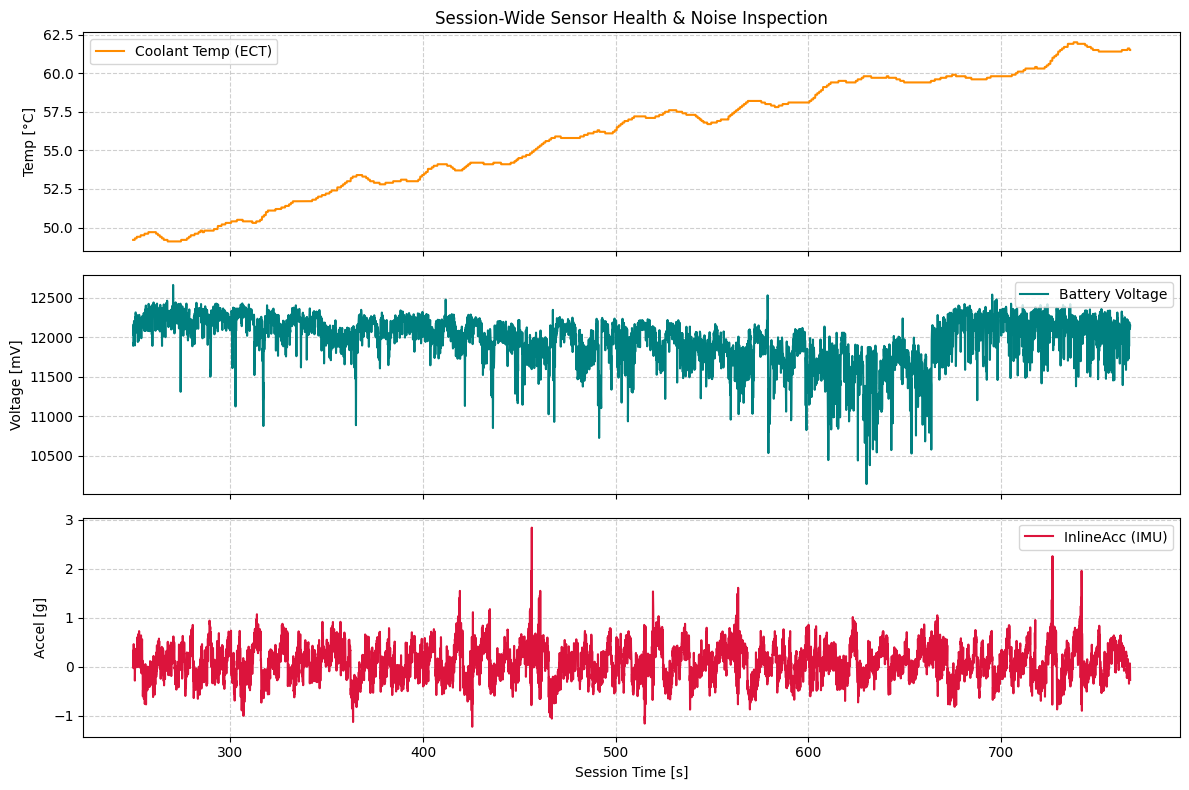

In [16]:
import matplotlib.pyplot as plt

# 1. Create a 3-panel plot sharing the session time axis (Figure and Axis)
fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)

# Plot 1: Engine Coolant Temperature (ECT)
axes[0].plot(session.data.index, session.data['ECT'], label='Coolant Temp (ECT)', color='darkorange')
axes[0].set_ylabel('Temp [°C]')
axes[0].set_title('Session-Wide Sensor Health & Noise Inspection')
axes[0].grid(True, linestyle='--', alpha=0.6)
axes[0].legend(loc='upper left')

# Plot 2: Battery Voltage (mV)
axes[1].plot(session.data.index, session.data['BATTERY'], label='Battery Voltage', color='teal')
axes[1].set_ylabel('Voltage [mV]')
axes[1].grid(True, linestyle='--', alpha=0.6)
axes[1].legend(loc='upper right')

# Plot 3: Longitudinal Acceleration (InlineAcc) to inspect vibration spikes
axes[2].plot(session.data.index, session.data['InlineAcc'], label='InlineAcc (IMU)', color ='crimson')
axes[2].set_ylabel('Accel [g]')
axes[2].set_xlabel('Session Time [s]')
axes[2].grid(True, linestyle='--', alpha=0.6)
axes[2].legend(loc='upper right')

plt.tight_layout()
plt.show()

#### Visual Inspection Observations:
* **Coolant Temperature (`ECT`):** Exhibits a smooth, monotonic warmup within an approximate range of `49.1°C` to `62.0°C` with minor cyclical fluctuations corresponding to straight-line airflow cooling and cornering loads. No sensor dropouts or spikes are present.
* **Battery Voltage (`BATTERY`):** Shows a gradual voltage sag with downward spikes below `10,500 mV` during Laps 1–4, followed by a sudden recovery and stabilization within a range of `11,500 mV` to `12,500 mV ` after approximately `t ≈ 660s` (start of Lap 5, the fastest and final lap). This points to either an intermittent battery terminal connection or charging system sensitivity to engine RPM.
* **Longitudinal Acceleration (`InlineAcc`):** Captures realistic braking baselines slightly below (`-1 g`) and acceleration up to (`+1 g`), while exhibiting sharp, isolated positive spikes up to nearly `+3 g` (e.g., around `t ≈ 450s`), confirming high-frequency chassis vibration noise rather than true vehicle acceleration.

## 8. Executive Summary & Data Cleaning Roadmap

### 1. Dataset Integrity & Continuity
* **Scope:** `10,350` telemetry samples covering `5` complete timed laps at **Serres Circuit** (Rider: Lambros).
* **Timing & Completeness:** Strictly consistent `20 Hz` (`dt = 0.0500s`) sampling rate with `0` missing values (`NaN`) and `0` duplicate timestamps.

### 2. Sensor Quality & Engineering Findings
* **Inactive Channels:** `26` constant/diagnostic channels were flagged by automated validation (`RPM`, `AFR`, `IAT`, `ENG_DIAG_*`, `ANALOG_DIAG_*`, `SPARE_*`), meaning fuel mixture (`AFR`) and intake air temp (`IAT`) cannot be analyzed in this session.
* **Engine Speed (`RPM`) Discrepancy:** Active engine speed is recorded in `RPM_CHANNEL` (max `14,762 rpm`) and `RPM dup 2` (max `13,685 rpm`), differing by a constant scaling factor (`~1.078x`).
* **Chassis & Controls:** `TPS` (`0–100%`) and `GPS Speed` (`52.4–186.1 km/h`) are clean. `Brake_pressure` reaches `17.9%` of sensor full-scale (`100 bar` calibration) and exhibits minor negative zero-drift (`-0.72%`) when unapplied. `Front_Travel` shows `-7.51 mm` during full extension due to static-sag zeroing.
* **Hardware Alerts for Trackside Engineers:**
  1. Check battery terminals and charging regulator (voltage dropped to `10.14 V` before recovering in Lap 5).
  2. Engine coolant ran cool (`49–62°C`); consider radiator taping to reach optimal operating temperature (`75–85°C`).
  3. Confirm engine rev limiter with mechanics to select between `RPM_CHANNEL` and `RPM dup 2`.

### 3. Action Plan for Next Phase (`02_Data_Cleaning_Panther_Racing`)
1. **Dimensionality Reduction:** Drop all `26` zero-variance/diagnostic channels and redundant duplicate columns.
2. **Standardization:** Rename the verified active RPM channel to `RPM` for clean downstream analysis.
3. **Noise & Offset Correction:** Clip negative zero-drift noise on `Brake_pressure` (`lower=0`) and apply low-pass smoothing (rolling average) to `InlineAcc` to remove chassis vibration spikes.